# 07 | Brant and replication of the original analysis

Each continuous 45-second window yields 19 channels × 15 patches × 2,048 features. Extracting Brant embeddings and screening hundreds of thousands of features can take time.

**Run in Colab.** See the repository README for Drive access and input paths. Run cells in order and start with notebook 01. Generated files belong in the private working directory. Saved outputs show the original study run.


In [1]:
from pathlib import Path
import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata, iqr
from IPython.display import display

if 'EEG_WORK' not in os.environ:
    from google.colab import drive
    drive.mount('/content/drive')
project = Path('/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab')
work = Path(os.environ.get('EEG_WORK', project/'ورودی‌های خصوصی بازتحلیل'/'derived'))
cache = Path(os.environ.get('EEG_REFERENCE_DIR', work/'inputs'))
raw_dir = Path(os.environ.get('EEG_RAW', '/content/eeg_mcmi_raw'))
for path in [work,cache,raw_dir]:
    path.mkdir(parents=True,exist_ok=True)
os.chdir(work)
def drive_service():
    from google.colab import auth
    from googleapiclient.discovery import build
    auth.authenticate_user()
    return build('drive','v3',cache_discovery=False)
def read_existing_drive_file(service,file_id,destination):
    from googleapiclient.http import MediaIoBaseDownload
    temp=destination.with_suffix(destination.suffix+'.part')
    with temp.open('wb') as out:
        reader=MediaIoBaseDownload(out,service.files().get_media(fileId=file_id))
        done=False
        while not done:
            _,done=reader.next_chunk()
    temp.replace(destination)
if not (cache/'scores.xlsx').exists():
    original=Path('/content/drive/MyDrive/MCMI_results.xlsx')
    if original.exists():
        shutil.copyfile(original,cache/'scores.xlsx')
    else:
        read_existing_drive_file(drive_service(),'1EOvKbEfvLAQPTjizNE9DEUR9Ik8xBsiy',cache/'scores.xlsx')
scores = pd.read_excel(cache/'scores.xlsx',index_col=0)
assert scores.index.is_unique
manifest=work/'joint/manifest.json'
ids=sorted(s for s in [Path(v[0]).stem for v in json.loads(manifest.read_text())] if scores.loc[s,'سن']>=18) if manifest.exists() else []
channels='Fp1 Fp2 F3 F4 C3 C4 P3 P4 O1 O2 F7 F8 T3 T4 T5 T6 Fz Cz Pz'.split()
def figure(name):
    plt.tight_layout()
    plt.savefig(work/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()

Mounted at /content/drive


## Extract Brant embeddings from cleaned EEG

Each run creates a fresh directory and computes embeddings directly from the NPZ files produced by notebook 01. The public checkpoint is pinned and verified by SHA-256. The study used 500 Hz, while the public checkpoint configuration lists 250 Hz. Windows never cross gaps.


In [2]:
assert len(ids)==19, 'Run notebook 01 first.'
missing = [sid for sid in ids if not (work/'out'/(sid+'.npz')).is_file()]
if missing:
    raise FileNotFoundError(f'Cleaned EEG files are missing: {missing}')
from tempfile import mkdtemp
runs_dir = work/'brant_runs'
runs_dir.mkdir(exist_ok=True)
run_dir = Path(mkdtemp(prefix='fresh_', dir=runs_dir))
os.chdir(run_dir)
print('Fresh Brant run:', run_dir, flush=True)
import importlib.util,subprocess,sys
if importlib.util.find_spec('huggingface_hub') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','huggingface_hub'])
from huggingface_hub import hf_hub_download
model_path=hf_hub_download('braindecode/brant-pretrained','model.safetensors',revision='35a60f42fd55e1f2982da16ab543a874c011943c')
from pathlib import Path
import json, struct, hashlib
import numpy as np
import pandas as pd
from scipy.signal import welch
from scipy.special import softmax

with open(model_path,"rb") as f:
    assert hashlib.file_digest(f,'sha256').hexdigest()=='d659b52572f56005ff43b6e00c6933ba34fb189b0707eb435060e8ecf6b59332'
    f.seek(0)
    header=json.loads(f.read(struct.unpack('<Q',f.read(8))[0]))
    offset=f.tell()
weights={k:np.memmap(model_path,mode="r",offset=offset+v["data_offsets"][0],dtype="<f4",shape=tuple(v["shape"])) for k,v in header.items() if "shape" in v}
def linear(x,key):
    w=weights[key+".weight"]
    return (x.reshape(-1,x.shape[-1])@w.T+weights[key+".bias"]).reshape(*x.shape[:-1],len(w))
def norm(x,key):
    x=x-x.mean(-1,keepdims=True)
    return x/np.sqrt((x*x).mean(-1,keepdims=True)+1e-5)*weights[key+".weight"]+weights[key+".bias"]
def encode(x):
    f,p=welch(x,500,nperseg=1500)
    edges=[.5,4,8,12,16,20,24,30,40]
    masks=[(f>=a)&(f<=b) for a,b in zip(edges,edges[1:])]
    power=np.stack([np.trapezoid(p[...,m],f[m],axis=-1) for m in masks],-1).astype("f")
    key="temporal_encoder.input_embedding."
    x=linear(x,key+"proj.0")+softmax(power,-1)@weights[key+"band_encoding"]+weights[key+"positional_encoding"]
    for stage,depth in [('temporal',12),('spatial',5)]:
        if stage=='spatial': x=x.swapaxes(0,1).copy()
        b,t,d=x.shape
        for i in range(depth):
            key=f"{stage}_encoder.trans_enc.layers.{i}."
            att=key+"self_attn."
            qkv=(x.reshape(-1,d)@weights[att+"in_proj_weight"].T+weights[att+"in_proj_bias"]).reshape(b,t,3,16,128)
            q,k,v=qkv.transpose(2,0,3,1,4)
            z=(softmax((q@k.swapaxes(-1,-2))*np.float32(128**-.5),-1)@v).transpose(0,2,1,3).reshape(b,t,d)
            x=norm(x+linear(z,att+"out_proj"),key+"norm1")
            x=norm(x+linear(np.maximum(linear(x,key+"linear1"),0),key+"linear2"),key+"norm2")
    return x.swapaxes(0,1)
for path in [work/'out'/(sid+'.npz') for sid in ids]:
    out=Path('encoded')/path.name
    out.parent.mkdir(exist_ok=True)
    a=np.load(path)
    starts=a['start_sample']
    windows=[]
    for run in np.split(np.arange(len(starts)),np.where(np.diff(starts)!=1000)[0]+1):
        signal=a['eeg'][run].transpose(1,0,2).reshape(19,-1)
        for j in range(0,signal.shape[1]-22500+1,13500):
            windows.append(encode(signal[:,j:j+22500].reshape(19,15,1500)))
    assert windows and np.isfinite(windows).all()
    np.savez_compressed(out,mean=np.mean(windows,0),median=np.median(np.mean(windows,2),0),n=len(windows),channels=a['channels'])
    print(path,len(windows),flush=True)

Fresh Brant run: /content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/brant_runs/fresh_cxr7wwit


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.03GB            

model.safetensors: downloading bytes:           |  0.00B            

/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_01.npz 6
/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_02.npz 6
/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_03.npz 9
/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_04.npz 9
/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_05.npz 2
/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_07.npz 7
/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_09.npz 4
/content/drive/MyDrive/پژوهش EEG و میلون — گزارش و نوت‌بوک‌های Colab/ورودی‌های خصوصی بازتحلیل/derived/out/Subject_11.npz 10
/content/drive/

## Compare 19 channels and 57 scores

Average temporal tokens within each window and take the median across windows. The original notebook replication also retains the mean across windows with the full time axis.


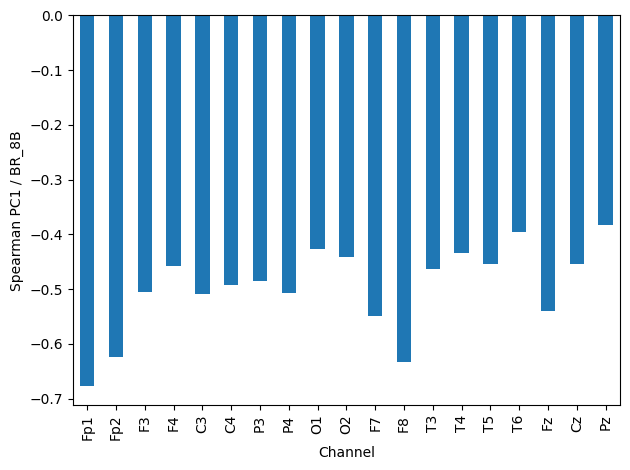

In [3]:
os.chdir(run_dir)
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.stats import rankdata,false_discovery_control
from sklearn.decomposition import PCA

def unit(a):
    return a/np.maximum(np.linalg.norm(a,axis=0),1e-20)
def centered(a):
    return unit(a-a.mean(axis=0))
def ucenter(a):
    n=len(a)
    s=a.sum(0)
    a=a-(s[:,None]+s)/(n-2)+s.sum()/((n-1)*(n-2))
    np.fill_diagonal(a,0)
    return a/max(np.linalg.norm(a),1e-20)
def channel_tests(V,ch,df,label):
    Y=df.to_numpy(float); n=len(Y); rank=rankdata(Y,axis=0); R=centered(rank)
    A=[]; D=[]; H=[]; exp=[]
    for x in V.transpose(1,0,2).astype(float):
        p=PCA(n_components=1,svd_solver='full').fit(x); A.append(centered(rankdata(p.transform(x)[:,0])));exp.append(p.explained_variance_ratio_[0])
        D.append(ucenter(cdist(x,x)).ravel())
        pred=np.zeros((n,n))
        for i in range(n):
            j=np.arange(n)!=i
            z=(x-x[j].mean(0))/np.where(x[j].std(0)>0,x[j].std(0),1)
            K=z@z.T/x.shape[1]
            w=np.linalg.solve(K[j][:,j]+np.eye(n-1),K[i,j])
            pred[i,j]=w+(1-w.sum())/(n-1)
        E=np.eye(n)-pred; H.append((E.T@E).ravel())
    A,D,H=map(np.asarray,(A,D,H))
    Z=np.stack([ucenter(cdist(v[:,None],v[:,None])) for v in rank.T],axis=-1)
    yc=Y-Y.mean(0); denom=(yc**2).sum(0)*(n/(n-1))**2
    Q=yc[:,None,:]*yc[None,:,:]/denom
    rng=np.random.default_rng(42); perms=np.stack([np.arange(n)]+[rng.permutation(n) for _ in range(10000)])
    def calc(P):
        b=len(P)
        def mul(M,t):
            return (M@t.swapaxes(0,1).reshape(M.shape[1],-1)).reshape(19,b,-1).transpose(1,0,2)
        def pairs(t):
            return t[P[:,:,None],P[:,None,:]].reshape(b,n*n,-1)
        return [mul(A,R[P]),mul(D,pairs(Z)),1-mul(H,pairs(Q))]
    obs=[m[0] for m in calc(perms[:1])]
    target=[abs(obs[0]),*obs[1:]]; hit=np.ones((3,19,57)); mx=hit.copy()
    for batch in np.array_split(perms[1:],200):
        for k,m in enumerate(calc(batch)):
            if k==0:m=abs(m)
            hit[k]+=(m>=target[k]-1e-12).sum(0)
            mx[k]+=(m.max((1,2))[:,None,None]>=target[k]-1e-12).sum(0)
    rows=[]
    for k,name in enumerate(['Spearman PC1','Distance association','LOO Q2']):
        pv=hit[k]/len(perms); q=false_discovery_control(pv.ravel()).reshape(pv.shape)
        for c,channel in enumerate(ch):
            for t,score in enumerate(df):
                rows.append([label,channel,score,name,obs[k][c,t],pv[c,t],q[c,t],mx[k,c,t]/len(perms),exp[c]])
    return pd.DataFrame(rows,columns=['Source','Channel','MCMI','Metric','Estimate','p_raw','q_BH','p_max','PC1_explained'])

def load():
    files=sorted(Path('encoded').glob('*.npz'))
    ids=[p.stem for p in files]
    assert len(ids)==19
    ch=np.load(files[0])['channels'].tolist()
    X=[]; V=[]; counts=[]
    for f in files:
        a=np.load(f); order=[a['channels'].tolist().index(c) for c in ch]
        X.append(a['mean'][order]); V.append(a['median'][order]);counts.append(int(a['n']))
    df=pd.read_excel(cache/'scores.xlsx',index_col=0).loc[ids]
    df=df[[c for c in df if c.startswith(('RAW_','BR_')) or c.endswith('_Score')]]
    df=df.loc[:,df.nunique()>1]
    assert df.shape==(19,57)
    return ids,[c.split('-')[0] for c in ch],np.array(X),np.array(V),counts,df

people,ch,mean,vec,counts,outcomes=load()
assert people==ids
results=channel_tests(vec,ch,outcomes,'Brant clean')
results.to_csv('brant_tests.csv',index=False)
order=[ch.index(c) for c in channels]
np.savez_compressed('brant_vectors.npz',ids=people,channels=channels,vectors=vec[:,order])
# Publish the newly extracted vectors at the input path used by notebook 08.
staging = work/f'{run_dir.name}_brant_vectors.npz'
shutil.copyfile(run_dir/'brant_vectors.npz', staging)
staging.replace(work/'brant_vectors.npz')
plot=results.query("MCMI=='BR_8B' and Metric=='Spearman PC1'").set_index('Channel')
plot.Estimate.plot.bar();plt.ylabel('Spearman PC1 / BR_8B');figure('07_brant_8B')

## Principal components, clustering, and prediction

Compare historical feature selection before validation with selection performed on training participants only. Use five participant-level folds, ridge and random forest models, and a training-mean baseline. Use the train-only protocol to interpret prediction performance.


fold 0
fold 1
fold 2
fold 3
fold 4


,model,score,OOF_RMSE,baseline_RMSE,Q2
50,train_only_ridge,BR_1,11.660470,11.429471,-0.040830
55,train_only_ridge,BR_4B,14.663353,17.593894,0.305387
62,train_only_ridge,BR_S,6.512712,6.654191,0.042071
74,train_only_ridge,BR_PP,7.121727,6.578157,-0.172093
75,train_only_RF,BR_1,11.802544,11.429471,-0.066348
80,train_only_RF,BR_4B,16.672146,17.593894,0.102036
87,train_only_RF,BR_S,6.218017,6.654191,0.126801
99,train_only_RF,BR_PP,6.643087,6.578157,-0.019839


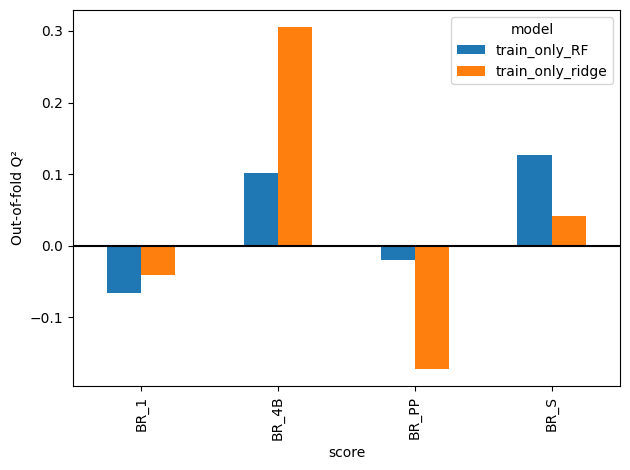

,tested,max_abs_r,max_abs_rho,joint_p_max,permutations
0,583680,0.852328,0.930464,0.0325,1999


,Unnamed: 0,0
0,selected,90.000000
1,max_abs_PC,0.878841
2,PC_global_p,0.167783
3,cluster_ARI,-0.016207
4,cell40_arbitrary_order_rho,-0.033019
5,cell41_descriptive_variance_ratio,1.121260


,delta,theta,alpha,beta1,beta2,gamma
BR_4B,0.371191,0.045854,0.095704,0.061045,0.130836,0.295370
BR_8B,0.413311,0.141949,0.053240,0.070320,0.219796,0.101383
BR_S,0.224490,0.036549,0.082157,0.065536,0.337735,0.253533


In [4]:
os.chdir(run_dir)
"""Participant-level replication of analysis.ipynb and train-only controls."""

import numpy as np,pandas as pd
from scipy.signal import welch
from scipy.stats import rankdata
from scipy.special import digamma
from scipy.linalg import eigh
from sklearn.model_selection import KFold
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.ensemble import RandomForestRegressor

def mi(x,y):
    # KSG k=3 in 1D/1D, sklearn's scaling and jitter convention.
    rng=np.random.RandomState(42)
    x=x.astype(float)/np.maximum(x.std(0),1e-15)
    x+=1e-10*np.maximum(1,abs(x).mean(0))*rng.normal(size=x.shape)
    y=y.astype(float)/max(y.std(),1e-15)
    y+=1e-10*max(1,abs(y).mean())*rng.normal(size=len(y))
    dy=abs(y[:,None]-y[None,:])[:,:,None]
    out=[]
    for a in np.array_split(x,max(1,(x.shape[1]+1023)//1024),axis=1):
        dx=abs(a[:,None,:]-a[None,:,:])
        radius=np.partition(np.maximum(dx,dy),3,axis=1)[:,3:4,:]
        out.extend(np.maximum(0,digamma(3)+digamma(len(y))-(digamma((dx<radius).sum(1))+digamma((dy<radius).sum(1))).mean(0)))
    return np.asarray(out)
def screen(x,y):
    r=centered(x).T@centered(y);s=centered(rankdata(x,axis=0)).T@centered(rankdata(y,axis=0))
    m=np.stack([mi(x,v) for v in y.T],1)
    top=np.zeros_like(m,bool);np.put_along_axis(top,np.argsort(m,axis=0)[-2:],True,axis=0)
    keep=(abs(r)>=.7)|(abs(s)>=.7)|top
    return r,s,m,keep
def rf(x,y,nt=50,depth=5):
    return RandomForestRegressor(n_estimators=nt,max_depth=depth,random_state=0).fit(x,y)
def run():
    ids,ch,mean,_,counts,df=load();n=len(ids)
    cols=[c for c in df if c.startswith('BR_') and c not in ['BR_X','BR_Y','BR_Z']]
    y=df[cols].to_numpy(float)
    def save(name,a,rows,cols):
        pd.DataFrame(a,index=rows,columns=cols).to_csv(name+'.csv')
    raw=[];power=[]
    for pid in ids:
        a=np.load(work/'out'/(pid+'.npz'));order=[list(a['channels']).index(c+'-LE') for c in ch];sig=a['eeg'][:,order,:]
        raw.append(sig.mean((0,2),dtype=float))
        f,p=welch(sig,500,nperseg=1000);p=p.mean(0)
        edges=[.5,4,8,12,20,30,40]
        masks=[(f>=a)&(f<=b) for a,b in zip(edges,edges[1:])]
        power.append(np.stack([np.trapezoid(p[:,m],f[m],axis=-1) for m in masks],1))
    power=np.asarray(power);band=['delta','theta','alpha','beta1','beta2','gamma']
    for name,x in [('EEG_mean',np.array(raw)),('embedding_mean',mean.mean((2,3),dtype=float))]:
        save(name,centered(x).T@centered(y),ch,cols)
    x=mean.reshape(n*19,-1).astype(float)
    gram=x@x.T
    def shared(tr):
        ix=(tr[:,None]*19+np.arange(19)).ravel()
        g=gram[:,ix]; g=g-g.mean(1,keepdims=True)-g[ix].mean(0)+g[ix].mean()
        w,v=eigh(g[ix],subset_by_index=(len(ix)-50,len(ix)-1)); basis=v[:,::-1]/np.sqrt(w[::-1])
        loadings=x[ix].T@basis
        sign=np.sign(loadings[np.argmax(abs(loadings),axis=0),np.arange(50)])
        return ((g@basis)*sign).reshape(n,950)
    allx=shared(np.arange(n));r,s,m,keep=screen(allx,y)
    features=[f'{c}_PC{k+1}' for c in ch for k in range(50)]
    for name,a in [('pearson',r),('spearman',s),('MI',m),('selected',keep.astype(int))]:
        save('PCA_'+name,a,features,cols)
    use=keep.any(1)
    # One synchronized permutation distribution for maximum absolute PC correlation (both statistics).
    rng=np.random.default_rng(42);U=centered(allx);V=centered(rankdata(allx,axis=0));Y=centered(y);R=centered(rankdata(y,axis=0))
    peak=max(abs(r).max(),abs(s).max());hits=0
    for _ in range(100):
        p=np.stack([rng.permutation(n) for j in range(100)])
        peaks=[]
        for a,b in [(U,Y),(V,R)]:
            t=(a.T@b[p].transpose(1,0,2).reshape(n,-1)).reshape(950,100,25)
            peaks.append(np.abs(t).max((0,2)))
        hits+=np.sum(np.maximum(*peaks)>=peak-1e-12)
    sel=allx[:,use];scorecl=KMeans(2,random_state=10).fit_predict(y);eegcl=KMeans(2,random_state=44).fit_predict(sel)
    save('clusters',np.stack([scorecl,eegcl],1),ids,['score','embedding_selected'])
    save('elbow',[[KMeans(k,random_state=0).fit(y).inertia_] for k in range(1,n+1)],range(1,n+1),['score_inertia'])
    tri=np.triu_indices(25,1)
    from scipy.stats import spearmanr
    arbitrary=spearmanr(np.corrcoef(y.T)[tri],np.corrcoef(sel.T)[:25,:25][tri]).statistic
    proj=PCA(n_components=n).fit(sel.T).transform(y.T)
    summary={'selected':int(use.sum()),'max_abs_PC':peak,'PC_global_p':(1+hits)/10001,'cluster_ARI':adjusted_rand_score(scorecl,eegcl),'cell40_arbitrary_order_rho':arbitrary,'cell41_descriptive_variance_ratio':np.mean(np.var(proj,axis=0)/np.var(y.T,axis=0))}
    pd.Series(summary).to_csv('screen_summary.csv')
    # BR_1 direct scan of 583680 coordinates.
    direct=mean.reshape(n,-1).astype(float);target=y[:,0]
    dr=centered(direct).T@centered(target);ds=centered(rankdata(direct,axis=0)).T@centered(rankdata(target));dm=mi(direct,target)
    i=np.unique(np.concatenate([np.flatnonzero((abs(dr)>=.75)&(abs(ds)>=.75)),np.flatnonzero((abs(ds)>=.75)&(abs(dr)<.4)),np.argsort(dm)[-50:],np.argsort(abs(dr))[-10:],np.argsort(abs(ds))[-10:]]))
    save('BR1_raw_screen',np.stack([dr[i],ds[i],dm[i]],1),[f'{ch[j//30720]}_patch{1+j%30720//2048}_dim{1+j%2048}' for j in i],['r','rho','MI'])
    # Prediction. Both faithful target-informed selection and a train-only control.
    splits=list(KFold(5,shuffle=True,random_state=0).split(y))
    outputs={};baseline=np.empty_like(y)
    def update(name,tr,te,z,mask,channel=False,legacy=False):
        xs=z[:,mask]
        for alg in ['ridge','RF'] if not channel else ['RF']:
            key=name+'_'+alg
            if key not in outputs:outputs[key]=np.zeros_like(y)
            if not xs.shape[1]:outputs[key][te]=y[tr].mean(0);continue
            if alg=='ridge':
                reduced=PCA(5).fit(xs if legacy else xs[tr]).transform(xs)
                outputs[key][te]=Ridge(alpha=1).fit(reduced[tr],y[tr]).predict(reduced[te])
            else:
                for j,v in enumerate(y.T): outputs[key][te,j]=rf(xs[tr],v[tr]).predict(xs[te])
    for fold,(tr,te) in enumerate(splits):
        print('fold',fold,flush=True);baseline[te]=y[tr].mean(0)
        z=shared(tr);mk=screen(z[tr],y[tr])[-1].any(1)
        update('legacy',tr,te,allx,use,legacy=True);update('train_only',tr,te,z,mk)
        for i,c in enumerate(ch):
            ix=np.arange(950)//50==i
            update('legacy_'+c,tr,te,allx,use&ix,True)
            update('train_only_'+c,tr,te,z,mk&ix,True)
            update('power_'+c,tr,te,power[:,i],np.ones(6,bool),True)
    rows=[]
    for key,pred in outputs.items():
        err=(pred-y)**2
        folds=np.stack([err[te].mean(0) for tr,te in splits])
        for i,c in enumerate(cols):
            rows.append([key,c,np.sqrt(err[:,i].mean()),np.sqrt(folds[:,i]).mean(),folds[:,i].mean(),1-err[:,i].sum()/((baseline-y)[:,i]**2).sum(),np.sqrt(((baseline-y)[:,i]**2).mean())])
    pd.DataFrame(rows,columns=['model','score','OOF_RMSE','mean_fold_RMSE','mean_fold_MSE','Q2','baseline_RMSE']).to_csv('prediction.csv',index=False)
    for name,z in [('all_channels',power.reshape(n,-1)),('channel_mean',power.mean(1))]:
        imp=[rf(z,v,300,None).feature_importances_.reshape(-1,6).sum(0) for v in y.T];save('band_importance_'+name,imp,cols,band)
run()

import numpy as np,pandas as pd
from scipy.stats import rankdata

ids,ch,X,V,counts,df=load()
y=df.BR_1.values;x=X.reshape(19,-1)
rng=np.random.default_rng(42)
idx=np.vstack([np.arange(19),[rng.permutation(19) for _ in range(1999)]])
peaks=np.zeros((2,len(idx)))
for j,(Y,rank) in enumerate([(y,False),(rankdata(y),True)]):
    yp=centered(Y)[idx].astype('f')
    for block in np.array_split(x,96,axis=1):
        if rank:block=rankdata(block,axis=0)
        col=centered(block.astype(float)).astype('f')
        peaks[j]=np.maximum(peaks[j],np.abs(yp@col).max(axis=1))
maxima=peaks.max(0)
pd.DataFrame([{'tested':x.shape[1],'max_abs_r':peaks[0,0],'max_abs_rho':peaks[1,0],'joint_p_max':np.mean(maxima>=maxima[0]-1e-7),'permutations':1999}]).to_csv('BR1_raw_control.csv',index=False)

"""Fold-level Ridge and forest metrics following notebook cells 43 and 44."""


from sklearn.metrics import r2_score
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold
import numpy as np,pandas as pd
ids,ch,mean,v,counts,df=load();y=df.loc[:,[c for c in df if c.startswith('BR_') and c not in ['BR_X','BR_Y','BR_Z']]]
n=len(ids);x=mean.reshape(n*19,-1).astype(float)
# Use exact small-Gram projection and orientation from the main analysis for determinism.
from scipy.linalg import eigh
gram=x@x.T
def shared(tr):
    ix=(tr[:,None]*19+np.arange(19)).ravel()
    g=gram[:,ix];g=g-g.mean(1,keepdims=True)-g[ix].mean(0)+g[ix].mean()
    w,v=eigh(g[ix],subset_by_index=(len(ix)-50,len(ix)-1));basis=v[:,::-1]/np.sqrt(w[::-1])
    loads=x[ix].T@basis;sign=np.sign(loads[np.argmax(abs(loads),axis=0),np.arange(50)])
    return ((g@basis)*sign).reshape(n,-1)
globalx=shared(np.arange(n));globalmask=pd.read_csv('PCA_selected.csv',index_col=0).any(axis=1).to_numpy()
output=[]
for fold,(tr,te) in enumerate(KFold(5,shuffle=True,random_state=0).split(y)):
    z=shared(tr);mk=screen(z[tr],y.iloc[tr].values)[-1].any(1)
    for label,a in [('legacy',globalx[:,globalmask]),('train_only',z[:,mk])]:
        red=PCA(5).fit(a if label=='legacy' else a[tr]).transform(a)
        for col in y:
            t=y[col].values
            for algo,pr in [('ridge',Ridge(alpha=1).fit(red[tr],t[tr]).predict(red[te])),('RF',rf(a[tr],t[tr]).predict(a[te]))]:
                output.append([label+'_'+algo,col,fold+1,r2_score(t[te],pr),np.mean((t[te]-pr)**2)])
pd.DataFrame(output,columns=['model','score','fold','R2','MSE']).to_csv('global_fold_scores.csv',index=False)


pred=pd.read_csv('prediction.csv')
table=pred.query("model in ['train_only_ridge','train_only_RF'] and score in ['BR_4B','BR_1','BR_S','BR_PP']")
display(table[['model','score','OOF_RMSE','baseline_RMSE','Q2']])
table.pivot(index='score',columns='model',values='Q2').plot.bar();plt.axhline(0,color='black');plt.ylabel('Out-of-fold Q²');figure('07_prediction')
display(pd.read_csv('BR1_raw_control.csv'))
display(pd.read_csv('screen_summary.csv'))
display(pd.read_csv('band_importance_channel_mean.csv',index_col=0).loc[['BR_4B','BR_8B','BR_S']])

## Correlation of 4B predictions with observed scores

Calculate an out-of-fold prediction per adult for comparison with the CNN paper. Select features within each training fold.


Pearson r / Ridge and RF [0.54151947 0.28203236]


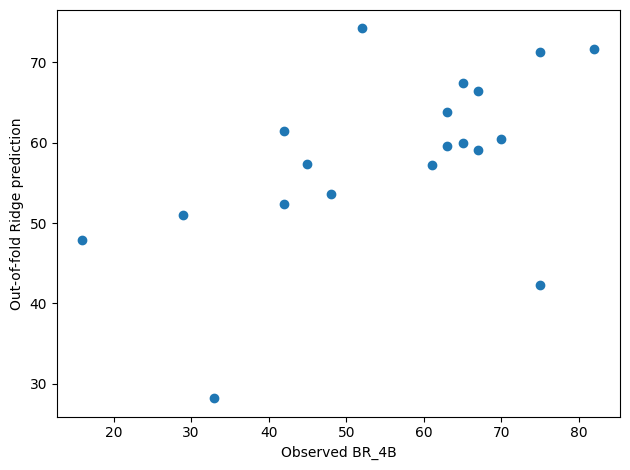

In [5]:
os.chdir(run_dir)
def mi(x,y):
    # KSG k=3 in 1D/1D, sklearn's scaling and jitter convention.
    rng=np.random.RandomState(42)
    x=x.astype(float)/np.maximum(x.std(0),1e-15)
    x+=1e-10*np.maximum(1,abs(x).mean(0))*rng.normal(size=x.shape)
    y=y.astype(float)/max(y.std(),1e-15)
    y+=1e-10*max(1,abs(y).mean())*rng.normal(size=len(y))
    dy=abs(y[:,None]-y[None,:])[:,:,None]
    out=[]
    for a in np.array_split(x,max(1,(x.shape[1]+1023)//1024),axis=1):
        dx=abs(a[:,None,:]-a[None,:,:])
        radius=np.partition(np.maximum(dx,dy),3,axis=1)[:,3:4,:]
        out.extend(np.maximum(0,digamma(3)+digamma(len(y))-(digamma((dx<radius).sum(1))+digamma((dy<radius).sum(1))).mean(0)))
    return np.asarray(out)
def screen(x,y):
    r=centered(x).T@centered(y);s=centered(rankdata(x,axis=0)).T@centered(rankdata(y,axis=0))
    m=np.stack([mi(x,v) for v in y.T],1)
    top=np.zeros_like(m,bool);np.put_along_axis(top,np.argsort(m,axis=0)[-2:],True,axis=0)
    keep=(abs(r)>=.7)|(abs(s)>=.7)|top
    return r,s,m,keep
def rf(x,y,nt=50,depth=5):
    return RandomForestRegressor(n_estimators=nt,max_depth=depth,random_state=0).fit(x,y)

from scipy.linalg import eigh
from scipy.special import digamma
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
ids,ch,mean,_,counts,df=load()
clinical=[c for c in df if c.startswith('BR_') and c not in ['BR_X','BR_Y','BR_Z']]
y=df[clinical]; target=y.BR_4B.to_numpy(); n=len(target)
x=mean.reshape(n*19,-1).astype(float);gram=x@x.T
def shared(tr):
    ix=(tr[:,None]*19+np.arange(19)).ravel()
    g=gram[:,ix];g=g-g.mean(1,keepdims=True)-g[ix].mean(0)+g[ix].mean()
    w,v=eigh(g[ix],subset_by_index=(len(ix)-50,len(ix)-1));basis=v[:,::-1]/np.sqrt(w[::-1])
    loads=x[ix].T@basis;sign=np.sign(loads[np.argmax(abs(loads),axis=0),np.arange(50)])
    return ((g@basis)*sign).reshape(n,-1)

preds=np.zeros((n,2))
for train,test in KFold(5,shuffle=True,random_state=0).split(y):
    z=shared(train);keep=screen(z[train],y.iloc[train].to_numpy())[-1].any(1)
    z=z[:,keep]
    features=PCA(5).fit(z[train]).transform(z)
    preds[test,0]=Ridge(alpha=1).fit(features[train],target[train]).predict(features[test])
    preds[test,1]=rf(z[train],target[train]).predict(z[test])
print('Pearson r / Ridge and RF',np.corrcoef(np.column_stack([target,preds]).T)[0,1:])
plt.scatter(target,preds[:,0]);plt.xlabel('Observed BR_4B');plt.ylabel('Out-of-fold Ridge prediction');figure('07_4B_predictions')

## Does delta variability improve Brant prediction of BR_8B?

Compare Brant alone, delta variability alone, and their combination on the same five participant-level folds. The models use either one whole-scalp delta IQR or one IQR per channel. Fit scaling, feature selection, and PCA on training participants only. This follow-up is exploratory.


In [ ]:
from scipy.signal import welch
from sklearn.preprocessing import StandardScaler

# Use the embedding projection and training-only screen from the preceding cell.
# Compute the same relative delta IQR as notebooks 03–04.
delta_rows = []
for subject in ids:
    with np.load(work / 'out' / (subject + '.npz')) as record:
        names = [name.split('-')[0] for name in record['channels']]
        order = [names.index(channel) for channel in ch]
        freq, psd = welch(record['eeg'][:, order].astype(float), fs=500,
                          nperseg=500, noverlap=250, axis=-1)
    in_delta = (freq >= 2) & (freq < 4)
    in_total = (freq >= 2) & (freq < 30)
    channel_share = 100 * psd[..., in_delta].sum(-1) / psd[..., in_total].sum(-1)
    scalp_psd = psd.mean(axis=1)
    scalp_share = 100 * scalp_psd[..., in_delta].sum(-1) / scalp_psd[..., in_total].sum(-1)
    delta_rows.append(np.r_[iqr(scalp_share), iqr(channel_share, axis=0)])

delta = np.asarray(delta_rows)
assert delta.shape == (len(ids), 1 + len(ch)) and np.isfinite(delta).all()
target_8b = y['BR_8B'].to_numpy()
predictions = {'Training mean': np.empty(len(ids))}
for train, test in KFold(5, shuffle=True, random_state=0).split(y):
    predictions['Training mean'][test] = target_8b[train].mean()
    brant = shared(train)
    keep = screen(brant[train], y.iloc[train].to_numpy())[-1].any(axis=1)
    selected = brant[:, keep]
    reduced = PCA(5).fit(selected[train]).transform(selected)
    scaled = StandardScaler().fit(delta[train]).transform(delta)
    for algorithm, brant_features in [('Ridge', reduced), ('Random forest', selected)]:
        inputs = {'Brant only': brant_features}
        for label, values in [('Whole-scalp delta', scaled[:, :1]),
                              ('Channel delta', scaled[:, 1:])]:
            inputs[label + ' only'] = values
            inputs['Brant + ' + label] = np.column_stack((brant_features, values))
        for name, features in inputs.items():
            if algorithm == 'Ridge':
                model = Ridge(alpha=1).fit(features[train], target_8b[train])
            else:
                model = rf(features[train], target_8b[train])
            key = algorithm + ' | ' + name
            predictions.setdefault(key, np.empty(len(ids)))[test] = model.predict(features[test])

baseline_sse = np.sum((predictions['Training mean'] - target_8b) ** 2)
delta_comparison = pd.DataFrame([
    {'Model and inputs': key, 'RMSE': np.sqrt(np.mean((pred - target_8b) ** 2)),
     'Q2': 1 - np.sum((pred - target_8b) ** 2) / baseline_sse}
    for key, pred in predictions.items()
])
delta_comparison.to_csv(run_dir / 'brant_delta_br8b.csv', index=False)
display(delta_comparison.round(4))
